# 15. Homogeneous Spaces

**Primary source:** Bronstein, Bruna, Cohen, and Veličković, *Geometric Deep Learning: Grids, Groups, Graphs, Geodesics, and Gauges*, §4.3, “Groups and Homogeneous Spaces” ([arXiv:2104.13478](https://arxiv.org/abs/2104.13478)).

**Supplementary mathematical source:** Loring W. Tu, *Introductory Lectures on Equivariant Cohomology*, §1.3, “Homogeneous Spaces”.

The notebook develops the group-action viewpoint behind homogeneous domains and convolution beyond flat grids. The spherical-convolution section is more detailed because it illustrates a key distinction: the sphere is the signal domain, while the full rotation group is the natural domain of the resulting correlation feature map.

Each code cell is preceded by a short explanation of what it demonstrates. The numerical experiments illustrate the ideas; they are not proofs of smooth or measure-theoretic statements.

## 1. From grids to homogeneous spaces

For a periodic grid, translation moves every point to every other point. Since every location has the same structure, one filter can be reused at all locations. This is the geometric reason convolution and translation equivariance fit together.

A group $G$ acts on a domain $\Omega$. The domain is **homogeneous** when the action is transitive:

$$\forall u,v\in\Omega,\quad \exists g\in G\text{ such that }g\cdot u=v.$$

Intuitively, no point is privileged by the symmetry action. The sphere with rotations is another example; a generic irregular surface is not homogeneous under its full isometry group.

### The action definition

The proto-book's margin note makes explicit two axioms tacit in the transitivity sentence:

$$e\cdot u=u,\qquad g\cdot(h\cdot u)=(gh)\cdot u.$$

These are the identity and compatibility axioms for a group action. Transitivity is the additional property that makes the space homogeneous.

## 2. Orbits and stabilizers

The **orbit** of a point u is $G\cdot u=\{g\cdot u:g\in G\}$, and the **stabilizer** is $G_u=\{g\in G:g\cdot u=u\}$. An action is transitive exactly when there is one orbit.

- Rotations act transitively on $S^2$.
- Rotations about only the $z$-axis are not transitive on $S^2$: they preserve latitude.
- The full group $SO(3)$ is transitive on $S^2$, but the stabilizer of the north pole is isomorphic to $SO(2)$.

### Code cell — visualize a non-transitive action

This plots the orbit of one point under rotations about the $z$-axis. The orbit is a latitude circle, not the whole sphere, so this subgroup action is not transitive.

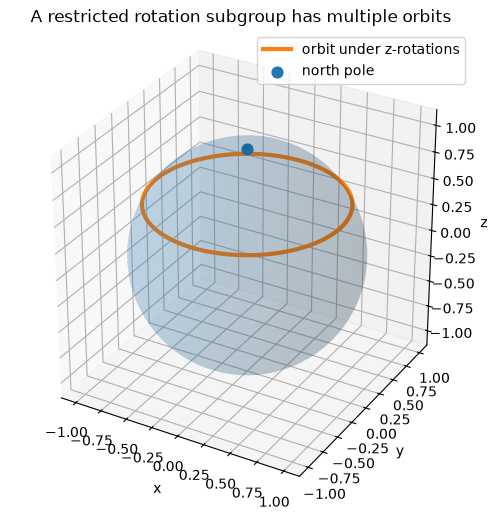

In [1]:
import numpy as np
import matplotlib.pyplot as plt

phi = np.linspace(0, 2*np.pi, 100)
theta = np.linspace(0, np.pi, 60)
X = np.outer(np.cos(phi), np.sin(theta))
Y = np.outer(np.sin(phi), np.sin(theta))
Z = np.outer(np.ones_like(phi), np.cos(theta))

latitude = np.pi / 3
orbit = np.column_stack([
    np.sin(latitude)*np.cos(phi),
    np.sin(latitude)*np.sin(phi),
    np.full_like(phi, np.cos(latitude))
])

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(X, Y, Z, alpha=0.15, linewidth=0)
ax.plot(orbit[:, 0], orbit[:, 1], orbit[:, 2], linewidth=3,
        label="orbit under z-rotations")
ax.scatter([0], [0], [1], s=60, label="north pole")
ax.set_box_aspect((1, 1, 1))
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
ax.set_title("A restricted rotation subgroup has multiple orbits")
ax.legend()
plt.show()

## 3. Homogeneous spaces as quotients \(G/H\)

Tu's §1.3 gives the smooth orbit–stabilizer theorem: if a Lie group $G$ acts smoothly and transitively on a smooth manifold (this topic is covered in the next notebook) $M$, and $H=G_p$ is the stabilizer of $p$, then

$$G/H\cong M,\qquad gH\longmapsto g\cdot p,$$

as a diffeomorphism under the theorem's hypotheses.

Why a **right coset** $gH$? If $g\cdot p=g'\cdot p$, then $g^{-1}g'\in H$, so $g'=gh$ for some $h\in H$. Thus all group elements sending the base point to the same point form one right coset. The quotient forgets precisely the part of the group action that does not change $p$.

This is a space of cosets, not generally a quotient group: $G/H$ is a group only when $H$ is normal.

### Example: spheres

The orthogonal group $O(n+1)$ acts transitively on $S^n \subset \mathbb R^{n+1}$. The stabilizer of $e_1$ is isomorphic to $O(n)$, hence

$$S^n\cong O(n+1)/O(n).$$

Similarly, the unitary group acts transitively on the unit sphere in $\mathbb C^{n+1}$:

$$S^{2n+1}\cong U(n+1)/U(n).$$

In particular, $S^2\cong SO(3)/SO(2)$: a rotation is determined up to a rotation about the north pole when only its image of the north pole matters.

### Code cell — numerical orbit–stabilizer illustration

Random rotations in $SO(3)$ send the north pole to points on the sphere and preserve their norms. This illustrates transitivity numerically; it does not prove the quotient diffeomorphism.

In [2]:
import numpy as np
from scipy.spatial.transform import Rotation

rng = np.random.default_rng(7)
north = np.array([0.0, 0.0, 1.0])
rotations = Rotation.random(8, random_state=rng)
points = rotations.apply(north)

print("Images of the north pole under random rotations:")
print(np.round(points, 3))
print("Norms (all should be 1):", np.round(np.linalg.norm(points, axis=1), 8))

Images of the north pole under random rotations:
[[-0.556 -0.169  0.814]
 [-0.907  0.368  0.204]
 [-0.93  -0.258 -0.261]
 [-0.955 -0.068 -0.288]
 [ 0.863 -0.237  0.447]
 [ 0.886  0.311 -0.345]
 [-0.088  0.166  0.982]
 [ 0.016 -0.152  0.988]]
Norms (all should be 1): [1. 1. 1. 1. 1. 1. 1. 1.]


## 4. Group actions on signals and equivariance

A scalar signal on $\Omega$ is a function $x:\Omega \to \mathcal C$. A common induced action on signals is

$$[\rho(g)x](u)=x(g^{-1}\cdot u).$$

The inverse ensures the left-representation convention $\rho(g) \rho(h)=\rho(gh)$. An operator $F$ is equivariant if

$$F(\rho(g)x)=\rho_{\mathrm{out}}(g)F(x).$$

Convolution is useful because it builds weight sharing into a linear operator in a way compatible with the symmetry. The quotient description clarifies that a location $u\in\Omega\cong G/H$ is not necessarily represented by a unique group element: different elements in the same coset represent the same location.

When $\Omega = \mathfrak G$, i.e., the group itself, the action becomes $(g, h) \mapsto gh$ and we obtain *regular representation* of $\mathfrak G$ on $\chi(\mathfrak G, \mathcal C):$

$$\rho(g)x(h) = x(g^{-1}h)$$

## 5. From ordinary convolution to group correlation

For a signal on the real line, the operation commonly called convolution in deep learning is often cross-correlation:

$$(x\star\theta)(u)=\int_{\mathbb R}x(v)\theta(u+v)\,dv.$$

The proto-book explicitly notes in the margin that this is technically **cross-correlation**, not mathematical convolution: the filter is not flipped in the classical way. Deep-learning libraries conventionally call this operation convolution.

For a group action on $\Omega$, group correlation can be written

$$(x\star\theta)(g)=\langle x,\rho(g)\theta\rangle
=\int_\Omega x(u)\theta(g^{-1}\cdot u)\,d\mu(u).$$

The output is indexed by $g\in G$, not necessarily by $u\in\Omega$. The proto-book's measure note matters: integration must use a suitable invariant measure. On finite domains this becomes a sum; on the sphere it is surface-area measure; on a locally compact group the natural framework uses Haar measure.

A first group correlation may therefore map a signal on a homogeneous space to a feature map on the group itself. Subsequent layers then operate on group-indexed features. (Taco elaborates this in his YouTube lecture.)

### Code cell — finite cyclic correlation and equivariance

A finite cyclic group turns the correlation into a sum. The code compares correlation after shifting the input with shifting the correlation output. This demonstrates equivariance for a finite periodic domain without interpolation.

Maximum equivariance error: 0.0


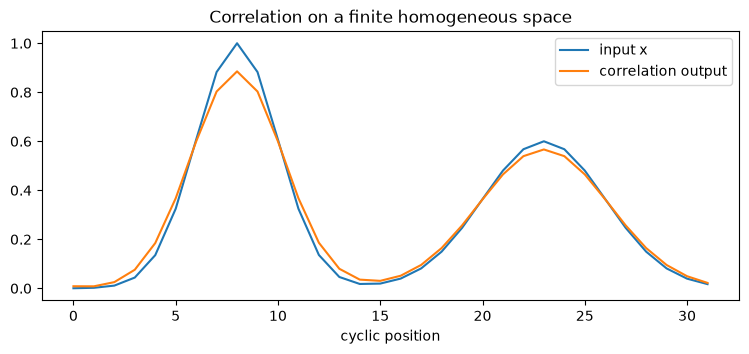

In [3]:
import numpy as np
import matplotlib.pyplot as plt

n = 32
u = np.arange(n)
x = np.exp(-0.5*((u - 8)/2.0)**2) + 0.6*np.exp(-0.5*((u - 23)/3.0)**2)
theta = np.array([0.2, 0.6, 1.0, 0.6, 0.2])
theta = theta / theta.sum()

def cyclic_correlation(signal, filt):
    # Correlate with periodic boundary conditions; shifts are modulo n.
    out = np.zeros_like(signal, dtype=float)
    center = len(filt)//2
    for g in range(len(signal)):
        for j, weight in enumerate(filt):
            offset = j - center
            out[g] += signal[(g + offset) % len(signal)] * weight
    return out

lhs = cyclic_correlation(np.roll(x, 5), theta)
rhs = np.roll(cyclic_correlation(x, theta), 5)
print("Maximum equivariance error:", np.max(np.abs(lhs - rhs)))

plt.figure(figsize=(9, 3.5))
plt.plot(u, x, label="input x")
plt.plot(u, cyclic_correlation(x, theta), label="correlation output")
plt.xlabel("cyclic position"); plt.legend()
plt.title("Correlation on a finite homogeneous space")
plt.show()

## 6. Spherical Convolution

### 6.1 The domain is $S^2$, the symmetry group is $SO(3)$

A spherical signal is a function $x:S^2\to\mathbb R^d$. Examples include all-sky maps of cosmic microwave background radiation, global weather fields, omnidirectional camera data, and directional molecular environments.

The rotation group

$$SO(3)=\{R\in\mathbb R^{3\times3}:R^TR=I,\;\det R=1\}$$

acts on the sphere by $u\mapsto Ru$. This action is transitive. However, $(S^2$ is two-dimensional while $SO(3)$ is three-dimensional: a point on the sphere specifies a direction, while a full rotation also specifies how a tangent frame is oriented around that direction. Rotations fixing a point form an $SO(2)$ stabilizer.

Thus

$$S^2\cong SO(3)/SO(2).$$

**Margin note elaborated:** the three degrees of freedom in a rotation are not the same as the two coordinates needed to locate a point on the sphere. A rotation mapping the north pole to a given point is not unique; one can compose it with any rotation about the north pole without changing that image.

### Code cell — visualize a rotation acting on the sphere

This plots a point on the unit sphere and its image under a rotation matrix. It demonstrates the \(SO(3)\)-action geometrically and checks that the image remains on the sphere.

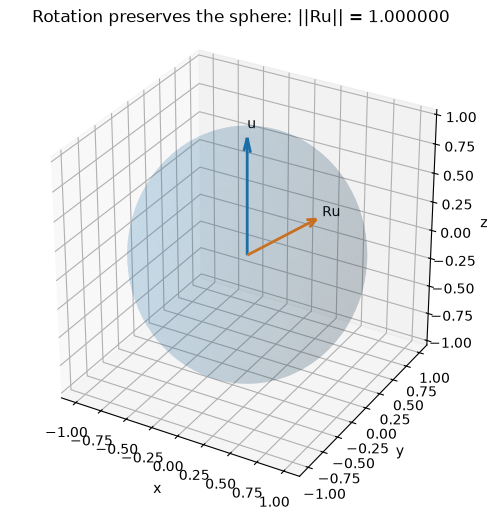

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation

u0 = np.array([0.0, 0.0, 1.0])
R = Rotation.from_euler("zyx", [35, 50, 20], degrees=True).as_matrix()
u1 = R @ u0

phi = np.linspace(0, 2*np.pi, 80)
theta = np.linspace(0, np.pi, 50)
Xs = np.outer(np.cos(phi), np.sin(theta))
Ys = np.outer(np.sin(phi), np.sin(theta))
Zs = np.outer(np.ones_like(phi), np.cos(theta))

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(Xs, Ys, Zs, alpha=0.12, linewidth=0)
ax.quiver(0, 0, 0, *u0, color="C0", linewidth=2, arrow_length_ratio=0.12)
ax.quiver(0, 0, 0, *u1, color="C1", linewidth=2, arrow_length_ratio=0.12)
ax.text(*(1.08*u0), "u")
ax.text(*(1.08*u1), "Ru")
ax.set_box_aspect((1, 1, 1))
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
ax.set_title(f"Rotation preserves the sphere: ||Ru|| = {np.linalg.norm(u1):.6f}")
plt.show()

### 6.2 Spherical cross-correlation formula

Let $x:S^2\to\mathbb R$ be a scalar signal and $\theta:S^2\to\mathbb R$ a filter/template. The proto-book's spherical formula is

$$(x\star\theta)(R)=\int_{S^2}x(u)\theta(R^{-1}u)\,d\omega(u),\qquad R\in SO(3),$$

where $d\omega$ is rotation-invariant surface-area measure. This is spherical **cross-correlation**: the filter is rotated and compared with the signal. A normalization factor such as $1/(4\pi)$ may be included if one wants an average rather than an area integral.

The output is a function on $SO(3)$. It measures how well the template matches the signal at each orientation. This differs from planar convolution, where translations are parametrized by the same two-dimensional plane on which the signal lives.

For a rotation $Q$, define the rotated signal by

$$[\rho(Q)x](u)=x(Q^{-1}u).$$

Then

$$(\rho(Q)x\star\theta)(R)=(x\star\theta)(Q^{-1}R),$$

under this convention and invariant measure. Rotating the input shifts the output over the rotation group. This is the symmetry principle exploited by spherical CNNs.

### 6.3 Deriving equivariance

Starting with the left-hand side,

$$\begin{aligned}
((\rho(Q)x)\star\theta)(R)
&=\int_{S^2}x(Q^{-1}u)\theta(R^{-1}u)\,d\omega(u).
\end{aligned}$$

Make the change of variables $v=Q^{-1}u$, so $u=Qv$. Rotation invariance gives $d\omega(u)=d\omega(v)$. Therefore

$$\begin{aligned}
((\rho(Q)x)\star\theta)(R)
&=\int_{S^2}x(v)\theta(R^{-1}Qv)\,d\omega(v)\\
&=\int_{S^2}x(v)\theta((Q^{-1}R)^{-1}v)\,d\omega(v)\\
&=(x\star\theta)(Q^{-1}R).
\end{aligned}$$

The invariance of the integration measure is essential. Without it, a change of variables could introduce a Jacobian factor and exact equivariance could fail.

### 6.4 An approximate numerical spherical correlation

This experiment samples points approximately uniformly on the sphere and evaluates a simple correlation score for several rotations. It uses nearest-neighbour lookup after rotating sample points, so the result is only a crude discretization—not a production spherical CNN or a proof of exact equivariance. Its purpose is to make the integral's “rotate a template, then compare” interpretation concrete.

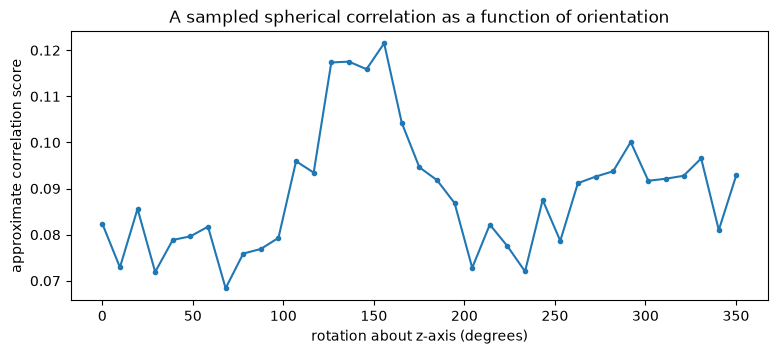

Score range: 0.0684 to 0.1215


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation
from scipy.spatial import cKDTree

def fibonacci_sphere(n):
    # Approximately uniform sample points on S^2.
    i = np.arange(n)
    z = 1 - 2*(i + 0.5)/n
    radius = np.sqrt(1 - z*z)
    angle = np.pi*(3 - np.sqrt(5))*i
    return np.column_stack([radius*np.cos(angle), radius*np.sin(angle), z])

N = 2500
points = fibonacci_sphere(N)
area_weight = 4*np.pi/N

def bump(directions, center, sharpness=18.0):
    center = np.asarray(center, dtype=float)
    center = center / np.linalg.norm(center)
    return np.exp(sharpness*(directions @ center - 1.0))

signal = bump(points, [0.2, -0.3, 0.93], 22) + 0.6*bump(points, [-0.7, 0.5, 0.4], 15)
template = bump(points, [0.0, 0.0, 1.0], 20) + 0.35*bump(points, [0.8, 0.0, 0.6], 12)

tree = cKDTree(points)
angles = np.linspace(0, 2*np.pi, 37, endpoint=False)
scores = []
for angle in angles:
    Rz = Rotation.from_euler("z", angle).as_matrix()
    # Row vectors: points @ Rz approximates the coordinates Rz^{-1}u.
    rotated_coords = points @ Rz
    idx = tree.query(rotated_coords, k=1)[1]
    scores.append(area_weight*np.sum(signal*template[idx]))

plt.figure(figsize=(9, 3.5))
plt.plot(np.degrees(angles), scores, marker="o", markersize=3)
plt.xlabel("rotation about z-axis (degrees)")
plt.ylabel("approximate correlation score")
plt.title("A sampled spherical correlation as a function of orientation")
plt.show()
print("Score range:", round(float(np.min(scores)), 4), "to", round(float(np.max(scores)), 4))

### 6.5 What makes spherical convolution different?

1. **No preferred chart.** Longitude–latitude images have coordinate singularities and nonuniform distortion near the poles. A planar CNN on such a raster is not automatically rotation-equivariant.
2. **The symmetry is global.** $SO(3)$ rotates the entire sphere; the filter is transported by the group action, not by shifting a rectangular patch.
3. **The output's base space changes.** The first correlation is indexed by rotations, so it lives on $SO(3)$, not just $S^2$.
4. **The measure matters.** The surface-area measure on $S^2$ is rotation invariant. A naive unweighted sum over an uneven latitude–longitude grid can introduce sampling bias.
5. **Spherical convolution is not the same as isotropic smoothing.** A kernel depending only on geodesic distance has extra symmetry and may collapse orientation information. A general oriented template can encode directional structure, with rotated matches indexed by $SO(3)$.
6. **Practical methods use harmonic analysis.** Cohen et al.'s *Spherical CNNs* uses generalized Fourier methods on the sphere/rotation group to implement rotation-equivariant correlations efficiently.

### 6.6 Why the next layer lives on $SO(3)$

The first spherical correlation maps

$$x:S^2\to\mathbb R^c\quad\longmapsto\quad x\star\theta:SO(3)\to\mathbb R^{c'}.$$

A second layer can correlate features over the group:

$$((x\star\theta)\star\phi)(R)
=\int_{SO(3)}(x\star\theta)(Q)\phi(R^{-1}Q)\,dQ,$$

where $dQ$ is Haar measure on $SO(3)$. This is how a stack of layers maintains a consistent equivariant feature representation. The first layer is adapted to the sphere as a homogeneous space; subsequent group layers operate on the group itself.

**Computational caveat from the proto-book:** exact integration over a continuous domain is generally not practical. Implementations discretize the sphere and rotation group, use quadrature/interpolation, or exploit harmonic analysis. The group $SO(3)$ has manageable dimension three, but its discretization and spectral transforms still require careful engineering.

## 7. Homogeneous does not mean Euclidean

A homogeneous space need not be a vector space, and its points need not support subtraction. Examples include:

- $\mathbb R^n$ under translations;
- a periodic grid under cyclic translations;
- $S^n\cong O(n+1)/O(n)$;
- $S^2\cong SO(3)/SO(2)$;
- complex projective space $\mathbb{CP}^n\cong U(n+1)/(U(1)\times U(n))$, with its usual action and stabilizer.

An arbitrary irregular finite set is not automatically homogeneous under a chosen transformation group. Transitivity must be checked for the specific action. A generic curved surface need not have a transitive isometry group; this is one reason the proto-book separates homogeneous spaces from general manifolds.

### Code cell — compare transitive and non-transitive finite actions

The code compares the cyclic group acting on a regular polygon with an action that cycles seven labels while fixing an eighth. The two orbits in the latter example demonstrate that homogeneity depends on the action, not merely on the underlying set.

In [6]:
def cyclic_action_orbit(n, point):
    return sorted({(point + k) % n for k in range(n)})

n = 8
print("Orbit of point 2 under cyclic shifts:", cyclic_action_orbit(n, 2))

# A non-transitive action: cycle labels 0,...,6 and fix label 7.
orbit_of_2 = sorted({(2 + k) % 7 for k in range(7)})
orbit_of_7 = [7]
print("Orbit of point 2 under restricted action:", orbit_of_2)
print("Orbit of point 7 under restricted action:", orbit_of_7)

Orbit of point 2 under cyclic shifts: [0, 1, 2, 3, 4, 5, 6, 7]
Orbit of point 2 under restricted action: [0, 1, 2, 3, 4, 5, 6]
Orbit of point 7 under restricted action: [7]


## 8. The side notes, collected and expanded

The proto-book's marginal notes in this section are useful mathematical reminders:

- **Action axioms are implicit.** Transitivity is meaningful only after a genuine group action has been specified: identity acts trivially and composition is compatible with the group product.
- **“Convolution” often means cross-correlation in deep learning.** The filter is matched against transformed copies without the classical kernel flip. The exact convention changes inverse signs but not the underlying equivariance principle when used consistently.
- **Integrate against an invariant measure.** The inner product used to compare a signal with a transformed filter must be compatible with the group action. Discrete sums, sphere area, and Haar integration are instances of this requirement.
- **The sphere and its rotation group have different dimensions.** $S^2$ is two-dimensional; $SO(3)$ is three-dimensional. A point on the sphere forgets the remaining rotation about that point, which is the stabilizer $SO(2)$.
- **A homogeneous space has no distinguished location under the action.** Every point can be moved to every other point. The action axioms are assumed alongside this transitivity condition.
- **Higher-dimensional symmetry groups can be expensive.** General theory is not automatically an efficient algorithm; discretization and harmonic structure are central to practice.

These notes connect the group-action formalism to implementation choices in equivariant neural networks.

## 9. Connection to the GDL blueprint

The GDL blueprint encourages local equivariant maps, nonlinearities, and suitable pooling/coarsening. Homogeneous spaces provide a setting where a shared template can be transported by a global group action. The quotient $G/H$ explains why the domain is not always the group itself; group correlation can lift a signal on $G/H$ to features indexed by $G$.

A useful conceptual progression is

$$\text{translations on }\mathbb R^n
\longrightarrow \text{group correlation on }G
\longrightarrow \text{correlation on }G/H
\longrightarrow \text{spherical CNNs on }S^2.$$

This does not mean every geometric domain admits the same simple convolution. General manifolds may lack a transitive global symmetry group; intrinsic geometry, geodesics, and local gauges then become important.

## 10. Examples and non-examples

**Examples**
- $S^n$ under $O(n+1)$: transitive, stabilizer $O(n)$, quotient $O(n+1)/O(n)$.
- $S^2$ under $SO(3)$: transitive, stabilizer $SO(2)$, quotient $SO(3)/SO(2)$.
- A periodic ring/grid under cyclic translations: transitive under the cyclic shift group.
- $\mathbb R^n$ under its translation group: transitive.

**Non-examples / cautions**
- $S^2$ under rotations around only one fixed axis: not transitive.
- An arbitrary irregular mesh under its automorphism group: typically not transitive; vertices may fall into multiple orbits.
- A quotient $G/H$ need not be a quotient group: that requires $H\triangleleft G$.
- A latitude–longitude raster plus an ordinary planar CNN is not automatically an $SO(3)$-equivariant spherical CNN.

## 11. Exercises

1. **Orbit–stabilizer on the sphere.** For the action of $SO(3)$ on $S^2$, identify the stabilizer of the north pole and explain why it is isomorphic to $SO(2)$.
2. **Cosets and points.** Show that $SO(3)/SO(2)\to S^2$, $R SO(2)\mapsto Re_3$, is well-defined and bijective. What theorem upgrades this to a diffeomorphism?
3. **Failure of transitivity.** Describe all orbits of rotations around the $z$-axis acting on $S^2$.
4. **Equivariance derivation.** Reproduce the change-of-variables proof of $(\rho(Q)x\star\theta)(R)=(x\star\theta)(Q^{-1}R)$, specifying where invariance of surface measure is used.
5. **Correlation convention.** Write both classical convolution and deep-learning cross-correlation on $\mathbb R$. Explain how replacing $g$ by $g^{-1}$ changes the formula.
6. **Second layer.** Explain why the output of the first spherical correlation is a function on $SO(3)$, and write the natural group-correlation formula for the next layer.
7. **Other homogeneous spaces.** Prove $S^{2n+1}\cong U(n+1)/U(n)$ by identifying the stabilizer of the first standard basis vector.
8. **Measure and discretization.** Why does a naive unweighted sum over an equally spaced latitude–longitude grid fail to approximate the spherical integral uniformly?
9. **Research thought.** What information could an orientation-indexed feature map on $SO(3)$ retain that a scalar feature map on $S^2$ might discard? Give an application where this matters.

## 12. Summary

- A homogeneous space is a transitive group-action domain.
- A transitive smooth Lie-group action identifies the manifold with $G/H$, where $H$ is a point stabilizer.
- Group correlation compares a signal with transformed copies of a filter using an invariant measure.
- “Convolution” in deep learning often denotes cross-correlation; inverse and sign conventions must be tracked carefully.
- For spherical signals, $SO(3)$ acts on $S^2$, and spherical correlation outputs a function on $SO(3)$.
- Rotation equivariance follows from a change of variables and invariance of surface-area measure.
- The distinction between domain and group matters when stacking layers; discretization and harmonic methods make the theory computationally practical.

## 13. Appendix A: Why Is Convolution So Important in Deep Learning?

A small clarification about the proto-book's organization: **§4.2, “Grids and Euclidean spaces,” develops convolution explicitly; §4.1, “Graphs and Sets,” is broader and emphasizes permutation symmetry and invariant aggregation rather than classical convolution in the same sense.** They fit together because both ask how to build learning operators that respect the structure of the data domain. The discussion in §4.3 then generalizes the grid story to group actions and homogeneous spaces.

### A.1 Convolution is a structured way to share parameters

Suppose an image contains a local pattern—an edge, corner, or texture. We usually want to detect that pattern regardless of where it occurs. A convolutional filter uses the **same parameters at every location**, rather than learning a different detector for each pixel. This weight sharing reduces the number of free parameters and encodes the prior that the same local pattern can matter anywhere.

For a signal \(x\) on a grid, a typical correlation-style layer has the form

$$
(T_\theta x)(u)=\sum_v x(v)\,\theta(u-v),
$$

up to the chosen sign and indexing convention. The same filter coefficients are reused as \(u\) varies. On continuous domains, the sum becomes an integral.

### A.2 Convolution is tied to translation equivariance

Let $S_a$ shift a signal by \(a\). A convolutional operator satisfies, under compatible conventions and boundary conditions,

$$
T_\theta(S_a x)=S_a(T_\theta x).
$$

This is **equivariance**, not invariance: shifting the input shifts the feature map in the corresponding way. A later operation, such as global pooling, may remove location information and produce an invariant prediction. The important point is that the intermediate representation preserves how the input transforms.

This algebraic relation is more than a convenient property of one architecture. On Euclidean grids, linear operators that commute with translations are characterized by convolution (with suitable assumptions). Thus convolution is not an arbitrary design choice: it is the natural form of a linear translation-equivariant operator.

### A.3 Why this matters for learning

Convolution combines several useful inductive biases:

- **Parameter sharing:** one local pattern detector is reused across the domain.
- **Locality:** a filter can focus on nearby interactions, matching the structure of many physical signals.
- **Statistical efficiency:** fewer independent parameters can mean less data is needed to learn a useful detector.
- **Compositionality:** stacked layers combine local features into larger-scale patterns and representations.
- **Symmetry compatibility:** translating the input translates the feature map, so the network need not relearn the same feature at every position.

These are inductive biases, not universal laws. If absolute location matters, if the data are not translation-like, or if boundary effects dominate, a plain convolutional layer may be insufficient or inappropriate.

### A.4 The geometric deep-learning generalization

The broader lesson is not that every domain should be forced into a rectangular grid. It is that we should identify the transformations that express the domain's structure and build operators compatible with them.

- On **grids**, translations lead to ordinary convolution.
- On **groups**, the same pattern-matching idea leads to group correlation/convolution.
- On **homogeneous spaces** $\Omega\cong G/H$, a signal lives on the space of cosets, while correlation can produce features indexed by the acting group.
- On **sets and graphs**, the relevant symmetry is usually relabelling by permutations. Permutation-invariant aggregation and permutation-equivariant message passing play the corresponding structural role, although a general graph message-passing layer is not simply ordinary Euclidean convolution.

For the sphere, this perspective gives spherical correlation: the input is a signal on $S^2$, rotations form $SO(3)$, and the first correlation produces an orientation-indexed feature map on $SO(3)$. The homogeneous-space description $S^2\cong SO(3)/SO(2)$ explains why these are distinct domains.

**The central answer:** convolution matters because it turns a prior about locality and symmetry into a learnable operator with shared parameters. In geometric deep learning, the goal is to understand that principle abstractly and then reconstruct the appropriate operator for each data domain—not to use the same convolution formula everywhere.

## Appendix B: “Convolution Is All You Need”

The slogan **“Convolution is all you need”** refers to a representation theorem for equivariant neural-network layers. In its general form, it states that, under suitable assumptions, **every linear equivariant map between the relevant feature spaces can be represented as a generalized convolution with an appropriately constrained kernel**. It is not a claim that convolution alone can solve every learning problem.

### B.1: The mathematical statement

Let $G$ be a symmetry group, and let $V_{\mathrm{in}}$ and $V_{\mathrm{out}}$ be spaces of input and output features on which $G$ acts. Write these actions as $\rho_{\mathrm{in}}(g)$ and $\rho_{\mathrm{out}}(g)$.

A linear map
$$
\Phi:V_{\mathrm{in}}\longrightarrow V_{\mathrm{out}}
$$
is **$G$-equivariant** if
$$
\Phi\bigl(\rho_{\mathrm{in}}(g)x\bigr)
=
\rho_{\mathrm{out}}(g)\Phi(x)
\qquad
\text{for every }g\in G.
$$

Equivariance says that transforming the input and then applying the map gives the same result as applying the map first and then transforming the output.

The theorem, in the setting of equivariant maps between suitable induced feature representations on homogeneous spaces, says that such a linear map can be written as a generalized convolution:
$$
\boxed{\Phi(x)=x\star\kappa,}
$$
where $\kappa$ is a kernel satisfying the appropriate symmetry constraints. The precise convolution formula and kernel constraints depend on the group, the spaces on which the features live, and how the features transform.

This is a characterization of the **most general linear equivariant layers** in that setting—not merely a recipe for constructing some equivariant layers.

### B.2: Why does this hold for ordinary CNNs?

Consider a signal $x:\mathbb{R}^d\to\mathbb{R}$ and a translation-equivariant linear operator $T$. Translation equivariance means
$$
T(S_a x)=S_a(Tx),
$$
where $S_a$ translates a signal by $a$.

Under standard assumptions, every such operator can be expressed as convolution or, with the common deep-learning convention, cross-correlation:
$$
(Tx)(u)=\int_{\mathbb{R}^d}x(v)\,
\kappa(u-v)\,dv.
$$

Thus, on a Euclidean grid, convolution is not an arbitrary architectural choice: it is the general form of a linear operator compatible with translations.

The same idea extends beyond translations. Replace the translation group by another symmetry group, and the appropriate generalized convolution describes the corresponding equivariant linear layers.

### B.3: From grids to groups and homogeneous spaces

The theorem provides a common mathematical framework for several architectures:

- **Euclidean grids:** translation equivariance leads to ordinary convolutional layers.
- **Group domains:** rotation or other group symmetries lead to group convolutions, with kernels constrained by the desired equivariance.
- **Homogeneous spaces:** when the domain is $G/H$, generalized convolution connects features on that space to group actions and representations.
- **Spherical data:** since $S^2\cong SO(3)/SO(2)$, spherical convolution can construct layers compatible with three-dimensional rotations.
- **Graphs and sets:** permutation-equivariant linear maps and message-passing operations are related to the same broader principle, although they are not all ordinary Euclidean convolutions and their precise characterization depends on the graph setting.

### B.4: What does this mean for neural-network design?

The theorem suggests a systematic design principle:

1. Identify the domain on which the data live.
2. Identify the symmetry group that should act on the data.
3. Specify how input and output features transform under that group.
4. Construct the most general linear equivariant layer—in the appropriate setting, a generalized convolution with a constrained kernel.
5. Combine these layers with suitable nonlinearities and other operations that preserve the desired equivariance.

This approach builds symmetry into the architecture rather than asking the model to learn it entirely from data. The resulting parameter sharing can improve statistical efficiency and ensure that predictions or feature transformations behave consistently under the specified symmetries.

### B.5: What the theorem does *not* say

The theorem does not say that every neural-network operation is a convolution, that convolution by itself is sufficient for every task, or that every equivariant map on every conceivable domain has this form without additional assumptions.

It characterizes a class of **linear equivariant maps**. A full neural network also involves nonlinearities, pooling or readout, and possibly other operations. These must be designed appropriately for the desired symmetry properties.

### Conclusion

The importance of “convolution is all you need” is that it turns symmetry into a characterization of the allowable learnable linear operators. Ordinary CNNs arise from translation symmetry; group-equivariant CNNs extend this idea to other groups; and spherical and other homogeneous-space architectures apply it to non-Euclidean domains.

**The central lesson of Geometric Deep Learning is not that convolution is universally the right formula, but that the domain and its symmetries determine the appropriate form of the learnable operator.**

## References

1. **Bronstein, M. M., Bruna, J., Cohen, T., & Veličković, P.** *Geometric Deep Learning: Grids, Groups, Graphs, Geodesics, and Gauges*. Proto-book, §4.3 “Groups and Homogeneous Spaces,” arXiv:2104.13478 (2021). https://arxiv.org/abs/2104.13478
2. **Tu, L. W.** *Introductory Lectures on Equivariant Cohomology*. Princeton University Press, 2020. §1.3 “Homogeneous Spaces,” printed p. 7. The attached copy is the source for the smooth orbit–stabilizer theorem and the sphere example.
3. **Cohen, T. S., Geiger, M., Köhler, J., & Welling, M.** “Spherical CNNs.” ICLR, 2018. https://arxiv.org/abs/1801.10130
4. **Cohen, T. S., Geiger, M., & Weiler, M.** “A General Theory of Equivariant CNNs on Homogeneous Spaces.” NeurIPS 32, 2019. https://arxiv.org/abs/1811.02017
5. **Cohen, T. S. & Welling, M.** “Group Equivariant Convolutional Networks.” ICML, PMLR 48, 2990–2999, 2016. https://proceedings.mlr.press/v48/cohenc16.html
6. Taco Cohen’s overview of the theorem and equivariant convolutional networks: https://tacocohen.wordpress.com/

The spherical-convolution derivation and implementation discussion are informed by the proto-book and the cited spherical/equivariant CNN literature.